# Notebook 07 — Transfer Need & Budget Optimizer
### Real Madrid AI Football Intelligence | Planning season 2026/27

**Goal:** translate the squad audit and external scouting shortlist into a transparent transfer-priority plan under an assumed **€200m project budget**.

This notebook does not invent transfer fees or claim that a player is available. It separates:
1. **Squad need** — a data-based signal from Real Madrid's 2025/26 squad depth and minutes;
2. **Scouting fit** — the position-aware score from Notebook 06;
3. **Budget feasibility** — calculated only for candidates with a manually verified fee/cost record.

> Important: €200m is a project scenario assumption, not a claim about Real Madrid's actual available cash. A market-value estimate is not the same as a transfer fee.

## 1. Context & Methods

### Decision question
Which positions should be prioritized for recruitment, and which combination of externally scouted players is feasible within the assumed budget **when verified costs are available**?

### Key assumptions
- Planning season: `2026/27`; squad baseline: `2025/26`.
- Project budget: `€200,000,000` (editable below).
- Minimum meaningful player sample: 450 league minutes for scouting candidates.
- The notebook uses broad position groups (`FW`, `MF`, `DF`); goalkeepers are excluded from this outfield-player optimizer.
- Squad minutes and player counts are indicators, not proof of a positional weakness.
- Unknown costs are **not** treated as zero and are excluded from the hard-budget optimization.
- Transfer fees must be supported by a source URL and a date. If only market value is known, label it as `market_value_estimate` and do not use it as a confirmed fee.

### 1.1 Configuration

In [1]:
from pathlib import Path
from itertools import combinations
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
# If this notebook is run from the notebooks/ folder, use its parent as project root.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

BUDGET_EUR = 200_000_000
MAX_SIGNINGS = 3
MIN_MINUTES = 450
BASELINE_SEASON = "2025/26"
TOP_CANDIDATES_PER_POSITION = 12

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
EXTERNAL_DIR = DATA_DIR / "external"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = PROJECT_ROOT / "figures"

for folder in [EXTERNAL_DIR, REPORTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Budget assumption: €{:,.0f}".format(BUDGET_EUR))

Project root: C:\Users\1alma\DataspellProjects\real-madrid-ai
Budget assumption: €200,000,000


## 2. Data

### 2.1 Locate upstream outputs
Expected inputs:
- Notebook 02: cleaned Real Madrid player-season dataset;
- Notebook 04: player ratings (if available);
- Notebook 06: external scouting shortlist.

The loader searches common filenames and fails with a clear message if the essential input is missing. Review the printed paths before interpreting results.

In [2]:
def find_first_existing(candidates, required=True, label="file"):
    for path in candidates:
        if path.exists():
            print(f"{label}: {path}")
            return path
    if required:
        tried = "\\n".join(str(p) for p in candidates)
        raise FileNotFoundError(f"Could not find {label}. Tried:\\n{tried}")
    print(f"Optional {label} not found.")
    return None

squad_path = find_first_existing([
    PROCESSED_DIR / "real_madrid_player_season_clean.csv",
    PROCESSED_DIR / "real_madrid_clean.csv",
    PROCESSED_DIR / "real_madrid_player_season_laliga_2023_2026_clean.csv",
    PROCESSED_DIR / "real_madrid_player_season_laliga_2023_2026.csv",
], label="Real Madrid cleaned player-season data")

shortlist_path = find_first_existing([
    PROCESSED_DIR / "external_scouting_shortlist_2025_26.csv",
    PROCESSED_DIR / "external_scouting_pool_2025_26.csv",
], label="External scouting shortlist/pool")

rating_path = find_first_existing([
    PROCESSED_DIR / "real_madrid_player_ratings.csv",
    PROCESSED_DIR / "player_ratings.csv",
    REPORTS_DIR / "player_ratings.csv",
], required=False, label="Optional player ratings")

squad_raw = pd.read_csv(squad_path)
scouting_raw = pd.read_csv(shortlist_path)
ratings_raw = pd.read_csv(rating_path) if rating_path else pd.DataFrame()

print("Squad rows:", len(squad_raw), "| scouting rows:", len(scouting_raw))
print("Squad columns:", list(squad_raw.columns)[:25])
print("Scouting columns:", list(scouting_raw.columns)[:25])

Real Madrid cleaned player-season data: C:\Users\1alma\DataspellProjects\real-madrid-ai\data\processed\real_madrid_player_season_clean.csv
External scouting shortlist/pool: C:\Users\1alma\DataspellProjects\real-madrid-ai\data\processed\external_scouting_shortlist_2025_26.csv
Optional player ratings: C:\Users\1alma\DataspellProjects\real-madrid-ai\data\processed\real_madrid_player_ratings.csv
Squad rows: 92 | scouting rows: 60
Squad columns: ['league', 'season', 'team', 'player_name', 'nation', 'pos', 'age', 'born', 'playing_time_mp', 'playing_time_starts', 'playing_time_min', 'playing_time_90s', 'performance_gls', 'performance_ast', 'performance_g_a', 'performance_g_pk', 'performance_pk', 'performance_pkatt', 'performance_crdy', 'performance_crdr', 'per_90_minutes_gls', 'per_90_minutes_ast', 'per_90_minutes_g_a', 'per_90_minutes_g_pk', 'per_90_minutes_g_a_pk']
Scouting columns: ['league', 'season', 'team', 'player', 'nation', 'pos', 'age', 'born', 'playing_time_mp', 'playing_time_start

### 2.2 Standardize fields

In [6]:
def first_existing_column(df, options):
    return next((c for c in options if c in df.columns), None)

def standardize_position(value):
    if pd.isna(value):
        return np.nan
    value = str(value).upper()
    if any(token in value for token in ["GK", "KEEPER"]):
        return "GK"
    if any(token in value for token in ["FW", "FW,"]):
        return "FW"
    if any(token in value for token in ["MF", "MID"]):
        return "MF"
    if any(token in value for token in ["DF", "DEF"]):
        return "DF"
    return np.nan

def prepare_squad(df):
    out = df.copy()
    aliases = {
        "season": ["season"],
        "player_name": ["player_name", "player", "name"],
        "position": ["position_group", "position", "pos"],
        "minutes": ["minutes", "playing_time_min", "min"],
        "age": ["age"],
        "team": ["team", "club"],
    }
    for target, options in aliases.items():
        source = first_existing_column(out, options)
        if source is None:
            if target in ["season", "player_name", "minutes"]:
                raise ValueError(f"Required squad field not found: {target}; tried {options}")
            out[target] = np.nan
        elif source != target:
            out[target] = out[source]
    out["minutes"] = pd.to_numeric(out["minutes"], errors="coerce")
    out["age"] = pd.to_numeric(out["age"], errors="coerce")
    out["position_group"] = out["position"].apply(standardize_position)
    out["season"] = out["season"].astype(str).str.strip()

    season_map = {
        "2324": "2023/24",
        "2425": "2024/25",
        "2526": "2025/26",
    }

    out["season"] = out["season"].replace(season_map)
    return out

def prepare_scouting(df):
    out = df.copy()
    aliases = {
        "player_name": ["player_name", "player", "name"],
        "team": ["team", "club"],
        "league": ["league", "competition"],
        "position": ["position_group", "position", "pos"],
        "minutes": ["minutes", "playing_time_min", "min"],
        "age": ["age"],
        "scouting_score": ["scouting_score", "position_score", "performance_score", "rating_score"],
    }
    for target, options in aliases.items():
        source = first_existing_column(out, options)
        if source is None:
            if target in ["player_name", "minutes"]:
                raise ValueError(f"Required scouting field not found: {target}; tried {options}")
            out[target] = np.nan
        elif source != target:
            out[target] = out[source]
    out["minutes"] = pd.to_numeric(out["minutes"], errors="coerce")
    out["age"] = pd.to_numeric(out["age"], errors="coerce")
    out["position_group"] = out["position"].apply(standardize_position)
    out["scouting_score"] = pd.to_numeric(out["scouting_score"], errors="coerce")
    return out

squad = prepare_squad(squad_raw)
scouting = prepare_scouting(scouting_raw)

print("Squad season coverage:", sorted(squad["season"].dropna().unique()))
print("Position groups in squad:", sorted(squad["position_group"].dropna().unique()))
print("Position groups in scouting pool:", sorted(scouting["position_group"].dropna().unique()))

Squad season coverage: ['2023/24', '2024/25', '2025/26']
Position groups in squad: ['DF', 'FW', 'GK', 'MF']
Position groups in scouting pool: ['DF', 'FW', 'MF']


## 3. Squad need assessment

We use the latest available Real Madrid season in the input, ideally 2025/26. For each outfield position, calculate:
- total minutes played by the position group;
- number of players with at least 450 minutes;
- share of squad minutes;
- minutes concentration among the top three players.

A higher need score means the position merits closer review. It is a **screening heuristic**, not a tactical assessment.

In [7]:
baseline = squad[squad["season"].eq(BASELINE_SEASON)].copy()
if baseline.empty:
    available = sorted(squad["season"].dropna().unique())
    raise ValueError(
        f"No rows for BASELINE_SEASON={BASELINE_SEASON}. Available seasons: {available}. "
        "Update BASELINE_SEASON in the configuration cell."
    )

outfield = baseline[baseline["position_group"].isin(["FW", "MF", "DF"])].copy()
outfield = outfield.dropna(subset=["minutes", "position_group"])
outfield["minutes"] = outfield["minutes"].clip(lower=0)

position_rows = []
for position, group in outfield.groupby("position_group"):
    player_minutes = (group.groupby("player_name", as_index=False)["minutes"]
                      .max().sort_values("minutes", ascending=False))
    total_minutes = player_minutes["minutes"].sum()
    active_count = int((player_minutes["minutes"] >= MIN_MINUTES).sum())
    top3_share = (player_minutes.head(3)["minutes"].sum() / total_minutes) if total_minutes else np.nan
    position_rows.append({
        "position_group": position,
        "players_450_plus": active_count,
        "total_position_minutes": total_minutes,
        "top3_minutes_share": top3_share,
        "top3_player_names": ", ".join(player_minutes.head(3)["player_name"].astype(str)),
    })

need = pd.DataFrame(position_rows)
if need.empty:
    raise ValueError("No outfield position data found for the baseline season.")

# Transparent heuristic: fewer established players and higher top-3 concentration increase the signal.
need["depth_component"] = 1 - (need["players_450_plus"] / max(need["players_450_plus"].max(), 1))
need["concentration_component"] = need["top3_minutes_share"].fillna(0)
need["need_score"] = 100 * (0.60 * need["depth_component"] + 0.40 * need["concentration_component"])
need = need.sort_values("need_score", ascending=False).reset_index(drop=True)
need

,position_group,players_450_plus,total_position_minutes,top3_minutes_share,top3_player_names,depth_component,concentration_component,need_score
0,FW,6,9372.0,0.711801,"Vinicius Júnior, Kylian Mbappé, Brahim Díaz",0.250,0.711801,43.472044
1,DF,7,11664.0,0.520748,"Álvaro Carreras, Dean Huijsen, Raúl Asencio",0.125,0.520748,28.329904
2,MF,8,13062.0,0.564156,"Federico Valverde, Aurélien Tchouaméni, Arda G...",0.000,0.564156,22.566223


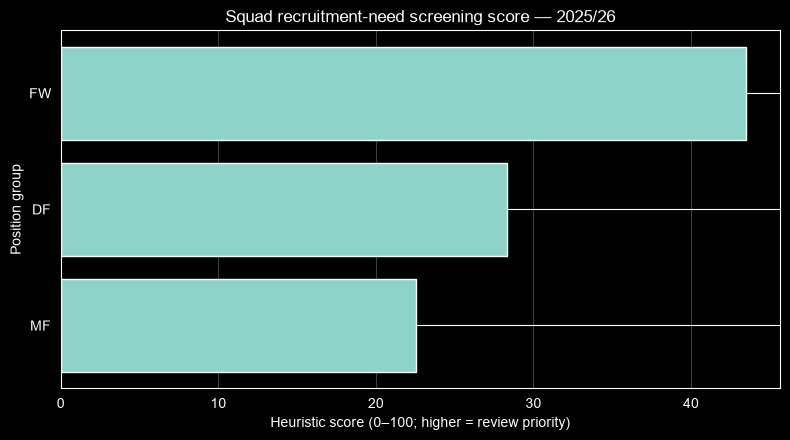

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_data = need.sort_values("need_score", ascending=True)
ax.barh(plot_data["position_group"], plot_data["need_score"])
ax.set_title(f"Squad recruitment-need screening score — {BASELINE_SEASON}")
ax.set_xlabel("Heuristic score (0–100; higher = review priority)")
ax.set_ylabel("Position group")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretation prompt
Read the chart together with `players_450_plus` and `top3_minutes_share`. Do not conclude that a position is weak based on the score alone: check injuries, tactical role, academy options, contracts and expected departures separately.

## 4. Scouting candidates and transfer-cost evidence

### 4.1 Match scouting candidates to positional need
The scouting score is normalized within position by Notebook 06. If a score column is missing, the notebook creates a transparent percentile score from available per-90 metrics. The fallback is a screening proxy and must be labeled as such.

In [9]:
# If Notebook 06 did not export a single score, use available metrics to create a position-wise percentile proxy.
metric_candidates = {
    "FW": ["goal_contributions_per_90", "goals_per_90", "shots_on_target_per_90"],
    "MF": ["goal_contributions_per_90", "assists_per_90", "tackles_won_per_90", "interceptions_per_90"],
    "DF": ["tackles_won_per_90", "interceptions_per_90", "crosses_per_90", "goal_contributions_per_90"],
}

for metric in ["goal_contributions_per_90", "goals_per_90", "assists_per_90",
               "shots_on_target_per_90", "tackles_won_per_90", "interceptions_per_90", "crosses_per_90"]:
    if metric in scouting.columns:
        scouting[metric] = pd.to_numeric(scouting[metric], errors="coerce")

if scouting["scouting_score"].notna().sum() == 0:
    scouting["scouting_score"] = np.nan
    for pos, metric_list in metric_candidates.items():
        mask = scouting["position_group"].eq(pos)
        available = [m for m in metric_list if m in scouting.columns and scouting.loc[mask, m].notna().sum() > 0]
        if available:
            pct = scouting.loc[mask, available].rank(pct=True) * 100
            scouting.loc[mask, "scouting_score"] = pct.mean(axis=1)
    scouting["score_method"] = "fallback position-wise mean percentile of available metrics"
else:
    scouting["score_method"] = "Notebook 06 scouting score"

scouting = scouting[scouting["position_group"].isin(["FW", "MF", "DF"])].copy()
scouting = scouting[scouting["minutes"].ge(MIN_MINUTES)].copy()

need_lookup = need.set_index("position_group")["need_score"].to_dict()
scouting["position_need_score"] = scouting["position_group"].map(need_lookup)
scouting["priority_score"] = (
    0.70 * scouting["scouting_score"].fillna(0) +
    0.30 * scouting["position_need_score"].fillna(0)
)
scouting = scouting.sort_values(["position_group", "priority_score"], ascending=[True, False])

display_cols = [c for c in [
    "player_name", "team", "league", "position_group", "age", "minutes",
    "scouting_score", "position_need_score", "priority_score", "score_method"
] if c in scouting.columns]
scouting[display_cols].groupby("position_group", group_keys=False).head(8)

,player_name,team,league,position_group,age,minutes,scouting_score,position_need_score,priority_score,score_method
0,Max Finkgräfe,RB Leipzig,GER-Bundesliga,DF,21,504,81.250000,28.329904,65.373971,fallback position-wise mean percentile of avai...
1,Alfonso Pedraza,Villarreal,ESP-La Liga,DF,29,1689,67.500000,28.329904,55.748971,fallback position-wise mean percentile of avai...
2,Quilindschy Hartman,Burnley,ENG-Premier League,DF,23,1825,65.000000,28.329904,53.998971,fallback position-wise mean percentile of avai...
3,Sergi Cardona,Villarreal,ESP-La Liga,DF,26,1970,63.125000,28.329904,52.686471,fallback position-wise mean percentile of avai...
14,Sergio Gómez,Real Sociedad,ESP-La Liga,DF,24,2701,61.250000,28.329904,51.373971,fallback position-wise mean percentile of avai...
17,João Cancelo,Barcelona,ESP-La Liga,DF,31,954,60.000000,28.329904,50.498971,fallback position-wise mean percentile of avai...
4,Lukas Kübler,Freiburg,GER-Bundesliga,DF,32,1587,59.375000,28.329904,50.061471,fallback position-wise mean percentile of avai...
10,Nnamdi Collins,Frankfurt,GER-Bundesliga,DF,21,1500,55.625000,28.329904,47.436471,fallback position-wise mean percentile of avai...
24,Harry Kane,Bayern Munich,GER-Bundesliga,FW,32,2377,100.000000,43.472044,83.041613,fallback position-wise mean percentile of avai...
28,Kylian Mbappé,Real Madrid,ESP-La Liga,FW,26,2599,86.666667,43.472044,73.708280,fallback position-wise mean percentile of avai...


### 4.2 Create a transfer-cost verification template
The template is created once. Fill it only with sourced evidence. Keep a URL and retrieval date for every cost. A `market_value_estimate` is not an agreed fee and will not enter the strict optimizer.

In [15]:
cost_template_path = EXTERNAL_DIR / "verified_transfer_costs_template.csv"
template_columns = [
    "player_name", "team", "league", "position_group",
    "cost_eur", "cost_type", "source_url", "retrieved_date",
    "notes"
]
if not cost_template_path.exists():
    pd.DataFrame(columns=template_columns).to_csv(cost_template_path, index=False)

print("Cost evidence template:", cost_template_path)
pd.read_csv(cost_template_path).head(10)

,player_name,team,league,position_group,cost_eur,cost_type,source_url,retrieved_date,notes


**Manual research standard:** use `confirmed_fee` only when a reliable source reports an agreed/official fee. If the source reports an estimate, use `market_value_estimate`. If the fee is unknown, leave `cost_eur` blank. Do not convert an estimate into a confirmed fee.

### 4.3 Merge cost evidence

In [11]:
costs = pd.read_csv(cost_template_path)
for col in template_columns:
    if col not in costs.columns:
        costs[col] = np.nan

costs["player_name_key"] = costs["player_name"].astype(str).str.strip().str.casefold()
scouting["player_name_key"] = scouting["player_name"].astype(str).str.strip().str.casefold()

scouting = scouting.merge(
    costs[["player_name_key", "cost_eur", "cost_type", "source_url", "retrieved_date", "notes"]],
    on="player_name_key", how="left", validate="many_to_one"
)
scouting["cost_eur"] = pd.to_numeric(scouting["cost_eur"], errors="coerce")
scouting["cost_verified"] = (
    scouting["cost_eur"].notna() &
    scouting["cost_type"].astype(str).str.casefold().eq("confirmed_fee") &
    scouting["source_url"].astype(str).str.startswith(("http://", "https://"))
)
scouting["cost_status"] = np.where(
    scouting["cost_verified"], "verified confirmed fee",
    np.where(scouting["cost_eur"].notna(), "estimate/unverified — excluded", "unknown — excluded")
)

scouting[display_cols + ["cost_eur", "cost_type", "cost_status"]].head(15)

,player_name,team,league,position_group,age,minutes,scouting_score,position_need_score,priority_score,score_method,cost_eur,cost_type,cost_status
0,Max Finkgräfe,RB Leipzig,GER-Bundesliga,DF,21,504,81.250,28.329904,65.373971,fallback position-wise mean percentile of avai...,NaN,NaN,unknown — excluded
1,Alfonso Pedraza,Villarreal,ESP-La Liga,DF,29,1689,67.500,28.329904,55.748971,fallback position-wise mean percentile of avai...,NaN,NaN,unknown — excluded
2,Quilindschy Hartman,Burnley,ENG-Premier League,DF,23,1825,65.000,28.329904,53.998971,fallback position-wise mean percentile of avai...,NaN,NaN,unknown — excluded
3,Sergi Cardona,Villarreal,ESP-La Liga,DF,26,1970,63.125,28.329904,52.686471,fallback position-wise mean percentile of avai...,NaN,NaN,unknown — excluded
4,Sergio Gómez,Real Sociedad,ESP-La Liga,DF,24,2701,61.250,28.329904,51.373971,fallback position-wise mean percentile of avai...,NaN,NaN,unknown — excluded
5,João Cancelo,Barcelona,ESP-La Liga,DF,31,954,60.000,28.329904,50.498971,fallback position-wise mean percentile of avai...,NaN,NaN,unknown — excluded
6,Lukas Kübler,Freiburg,GER-Bundesliga,DF,32,1587,59.375,28.329904,50.061471,fallback position-wise mean percentile of avai...,NaN,NaN,unknown — excluded
7,Nnamdi Collins,Frankfurt,GER-Bundesliga,DF,21,1500,55.625,28.329904,47.436471,fallback position-wise mean percentile of avai...,NaN,NaN,unknown — excluded
8,Adam Dźwigała,St Pauli,GER-Bundesliga,DF,29,1288,55.000,28.329904,46.998971,fallback position-wise mean percentile of avai...,NaN,NaN,unknown — excluded
9,Rayan Aït-Nouri,Manchester City,ENG-Premier League,DF,24,974,53.125,28.329904,45.686471,fallback position-wise mean percentile of avai...,NaN,NaN,unknown — excluded


## 5. Budget optimization

The optimizer selects up to `MAX_SIGNINGS` players, subject to:
- total verified fees no greater than the project budget;
- at most one signing per position group in this simplified scenario;
- candidates must have a verified `confirmed_fee`.

Objective: maximize the sum of `priority_score`. This is a transparent toy optimization, not a complete sporting-director model. It does not account for wages, agent fees, sell-on clauses, registration rules, contract length, squad registration or negotiation risk.

In [12]:
eligible = scouting[scouting["cost_verified"]].copy()
eligible = eligible.dropna(subset=["priority_score", "cost_eur"])
eligible = eligible[eligible["cost_eur"].ge(0)]

# Keep the candidate set small enough for transparent exhaustive enumeration.
eligible = (eligible.sort_values("priority_score", ascending=False)
            .groupby("position_group", group_keys=False)
            .head(TOP_CANDIDATES_PER_POSITION)
            .reset_index(drop=True))

best_combo = []
best_score = -np.inf
best_cost = 0.0

records = eligible.to_dict("records")
for count in range(1, min(MAX_SIGNINGS, len(records)) + 1):
    for combo in combinations(records, count):
        positions = [row["position_group"] for row in combo]
        if len(positions) != len(set(positions)):
            continue
        total_cost = sum(float(row["cost_eur"]) for row in combo)
        total_score = sum(float(row["priority_score"]) for row in combo)
        if total_cost <= BUDGET_EUR and total_score > best_score:
            best_combo = list(combo)
            best_score = total_score
            best_cost = total_cost

if best_combo:
    optimized_signings = pd.DataFrame(best_combo)
    optimized_signings["budget_share"] = optimized_signings["cost_eur"] / BUDGET_EUR
    display(optimized_signings[[
        "player_name", "team", "league", "position_group",
        "priority_score", "cost_eur", "cost_type", "source_url", "budget_share"
    ]])
    print(f"Total selected fees: €{best_cost:,.0f} / €{BUDGET_EUR:,.0f}")
    print(f"Budget remaining: €{BUDGET_EUR-best_cost:,.0f}")
    print(f"Combined priority score: {best_score:.2f}")
else:
    optimized_signings = pd.DataFrame()
    print("No feasible signing combination with verified confirmed fees.")
    print("This is expected if the cost evidence template is still empty.")
    print("Do not interpret missing cost evidence as evidence that players are free or unaffordable.")

No feasible signing combination with verified confirmed fees.
This is expected if the cost evidence template is still empty.
Do not interpret missing cost evidence as evidence that players are free or unaffordable.


## 6. Scenario and sensitivity checks

If no confirmed fees are available, report that the hard-budget optimization is **not yet decision-ready**. You can still inspect:
- the position priorities;
- the top scouting candidates by role;
- the share of candidates with verified fees.

Do not silently substitute market-value estimates for fees.

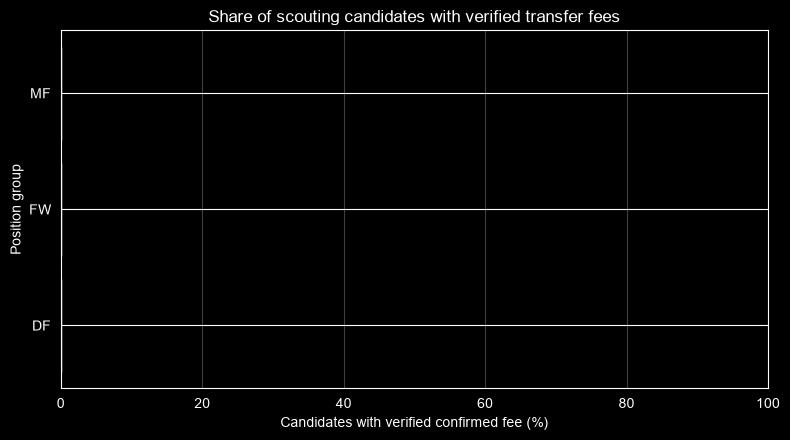

In [13]:
cost_coverage = scouting.groupby("position_group").agg(
    candidates=("player_name", "count"),
    verified_fee_candidates=("cost_verified", "sum"),
    top_priority=("priority_score", "max")
).reset_index()
cost_coverage["verified_fee_share"] = (
    cost_coverage["verified_fee_candidates"] / cost_coverage["candidates"].replace(0, np.nan)
)
display(cost_coverage)

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_data = cost_coverage.sort_values("verified_fee_share", ascending=True)
ax.barh(plot_data["position_group"], plot_data["verified_fee_share"].fillna(0) * 100)
ax.set_title("Share of scouting candidates with verified transfer fees")
ax.set_xlabel("Candidates with verified confirmed fee (%)")
ax.set_ylabel("Position group")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Decision output

This section creates a concise decision pack for the next dashboard/presentation notebook. The generated recommendation is deliberately conditional: it identifies where to investigate, not whom the club must sign.

In [17]:
position_output = need.copy()
position_output["planning_season"] = "2026/27"
position_output["baseline_season"] = BASELINE_SEASON
position_output["interpretation"] = "screening signal; validate with tactical and contract context"

# Exclude Real Madrid players from the external transfer shortlist
external_scouting = scouting[
    ~scouting["team"].astype(str).str.strip().str.casefold().isin([
        "real madrid",
        "real madrid cf"
    ])
].copy()

top_candidates = (
    external_scouting
    .sort_values("priority_score", ascending=False)
    .groupby("position_group", group_keys=False)
    .head(5)
)

display(
    top_candidates[[
        "player_name",
        "team",
        "league",
        "position_group",
        "age",
        "minutes",
        "scouting_score",
        "priority_score",
        "cost_status"
    ]]
)

candidate_columns = list(dict.fromkeys(
    display_cols + ["cost_status"]
))
candidate_output = top_candidates[candidate_columns].copy()

position_output.to_csv(REPORTS_DIR / "transfer_position_priorities_2026_27.csv", index=False)
candidate_output.to_csv(REPORTS_DIR / "transfer_candidate_shortlist_2026_27.csv", index=False)

if not optimized_signings.empty:
    optimized_signings.to_csv(REPORTS_DIR / "budget_optimized_signings_2026_27.csv", index=False)

summary = {
    "planning_season": "2026/27",
    "baseline_season": BASELINE_SEASON,
    "budget_assumption_eur": BUDGET_EUR,
    "max_signings": MAX_SIGNINGS,
    "scouting_candidates_after_minutes_filter": int(len(scouting)),
    "verified_confirmed_fee_candidates": int(scouting["cost_verified"].sum()),
    "optimizer_ready": bool(scouting["cost_verified"].any()),
    "selected_signings": int(len(optimized_signings)),
    "selected_fees_eur": float(best_cost) if best_combo else None,
    "highest_need_position": str(need.iloc[0]["position_group"]),
    "need_scores": {str(r["position_group"]): float(r["need_score"]) for _, r in need.iterrows()},
    "cost_template_path": str(cost_template_path),
    "limitations": [
        "Need score is a squad-depth heuristic, not a tactical diagnosis.",
        "No verified fee means candidate is excluded from hard-budget optimization.",
        "No wage, agent fee, contract, registration, injury or negotiation model.",
        "2025/26 league performance is not a guarantee of 2026/27 performance."
    ]
}
summary_path = REPORTS_DIR / "transfer_optimizer_summary_2026_27.json"
summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")

print("Saved:")
print("-", REPORTS_DIR / "transfer_position_priorities_2026_27.csv")
print("-", REPORTS_DIR / "transfer_candidate_shortlist_2026_27.csv")
print("-", summary_path)

Saved:
- C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\transfer_position_priorities_2026_27.csv
- C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\transfer_candidate_shortlist_2026_27.csv
- C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\transfer_optimizer_summary_2026_27.json


## 8. Takeaways and limitations

Use the outputs to write the final decision only after the notebook has run successfully.

Suggested reporting structure:
1. **Need:** state the highest-priority position and cite its score, established-player count and top-three minutes share.
2. **Scouting:** name the strongest candidates by role and explain which metrics support their ranking.
3. **Budget:** state whether enough candidates have verified confirmed fees for a valid optimization. If none, explicitly say the budget decision is pending price verification.
4. **Risks:** note sample-size, position classification, league comparability, contract/availability, and metric limitations.

### Validation checklist
- [ ] Correct 2025/26 squad baseline selected.
- [ ] Position groups and minutes look plausible.
- [ ] No duplicate candidate rows after cost merge.
- [ ] Every `confirmed_fee` has a valid source URL and retrieval date.
- [ ] Unknown/estimated costs are excluded from the hard-budget optimizer.
- [ ] Final recommendation is consistent with the generated CSVs and JSON summary.